# CogniStream: Developer Flow-State & Cognitive Load Analytics

This notebook analyzes developer productivity, task success, and cognitive load using the validated dataset. It is exploratory: relationships are associations, not causal claims.

## 1. Load the validated data

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("..") / "data" / "processed" / "ai_dev_productivity_cleaned.csv"
df = pd.read_csv(DATA_PATH)
display(df.head())
print(f"Rows: {len(df):,}; columns: {df.shape[1]}")

,hours_coding,coffee_intake_mg,distractions,sleep_hours,commits,bugs_reported,ai_usage_hours,cognitive_load,task_success
0,5.99,600,1,5.8,2,1,0.71,5.4,1
1,4.72,568,2,6.9,5,3,1.75,4.7,1
2,6.30,560,1,8.9,2,0,2.27,2.2,1
3,8.05,600,7,6.3,9,5,1.40,5.9,0
4,4.53,421,6,6.9,4,0,1.26,6.3,1


Rows: 500; columns: 9


The cleaned dataset contains 500 developer-task records and 9 numeric fields. The analysis uses the processed file so the raw source remains unchanged.

## 2. Data quality and schema

In [2]:
quality = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique(),
})
display(quality)
print("Duplicate rows:", int(df.duplicated().sum()))

,data_type,missing_values,unique_values
hours_coding,float64,0,353
coffee_intake_mg,int64,0,244
distractions,int64,0,9
sleep_hours,float64,0,67
commits,int64,0,14
bugs_reported,int64,0,6
ai_usage_hours,float64,0,260
cognitive_load,float64,0,79
task_success,int64,0,2


Duplicate rows: 0


All fields are numeric, which is appropriate for this dataset. Missing values and duplicate rows should be zero after the cleaning step; any non-zero value would require investigation before analysis.

## 3. Descriptive statistics

In [3]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
hours_coding,500.0,5.02,1.95,0.0,3.60,5.03,6.28,12.00
coffee_intake_mg,500.0,463.19,142.33,6.0,369.50,500.50,600.00,600.00
distractions,500.0,2.98,1.68,0.0,2.00,3.00,4.00,8.00
sleep_hours,500.0,6.98,1.46,3.0,6.10,6.95,7.90,10.00
commits,500.0,4.61,2.70,0.0,3.00,5.00,6.00,13.00
bugs_reported,500.0,0.86,1.10,0.0,0.00,0.00,2.00,5.00
ai_usage_hours,500.0,1.51,1.09,0.0,0.70,1.26,2.07,6.36
cognitive_load,500.0,4.50,1.87,1.0,3.18,4.40,5.80,10.00
task_success,500.0,0.61,0.49,0.0,0.00,1.00,1.00,1.00


The descriptive table gives the scale and spread of each metric. It is the baseline for interpreting later comparisons between successful and unsuccessful tasks.

## 4. Task-success balance

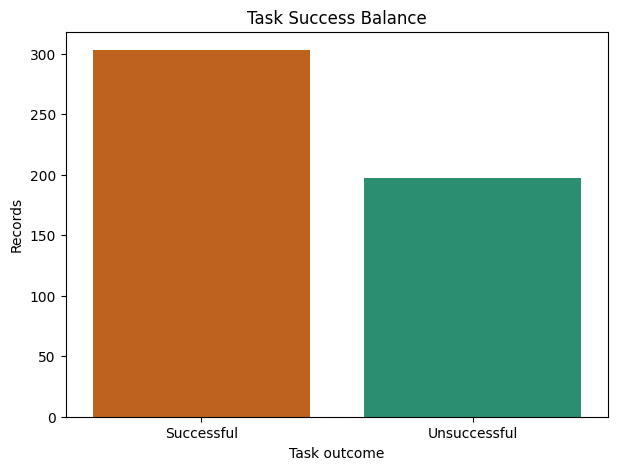

Successful      303
Unsuccessful    197
Name: task_success, dtype: int64


In [4]:
outcome_counts = df["task_success"].map({0: "Unsuccessful", 1: "Successful"}).value_counts()
plt.figure(figsize=(7, 5))
sns.barplot(x=outcome_counts.index, y=outcome_counts.values, hue=outcome_counts.index, legend=False, palette=["#d95f02", "#1b9e77"])
plt.title("Task Success Balance")
plt.xlabel("Task outcome")
plt.ylabel("Records")
plt.show()
print(outcome_counts)

The target is moderately imbalanced rather than perfectly even. Model evaluation, if added later, should therefore include precision, recall and F1-score instead of relying only on accuracy.

## 5. Feature distributions

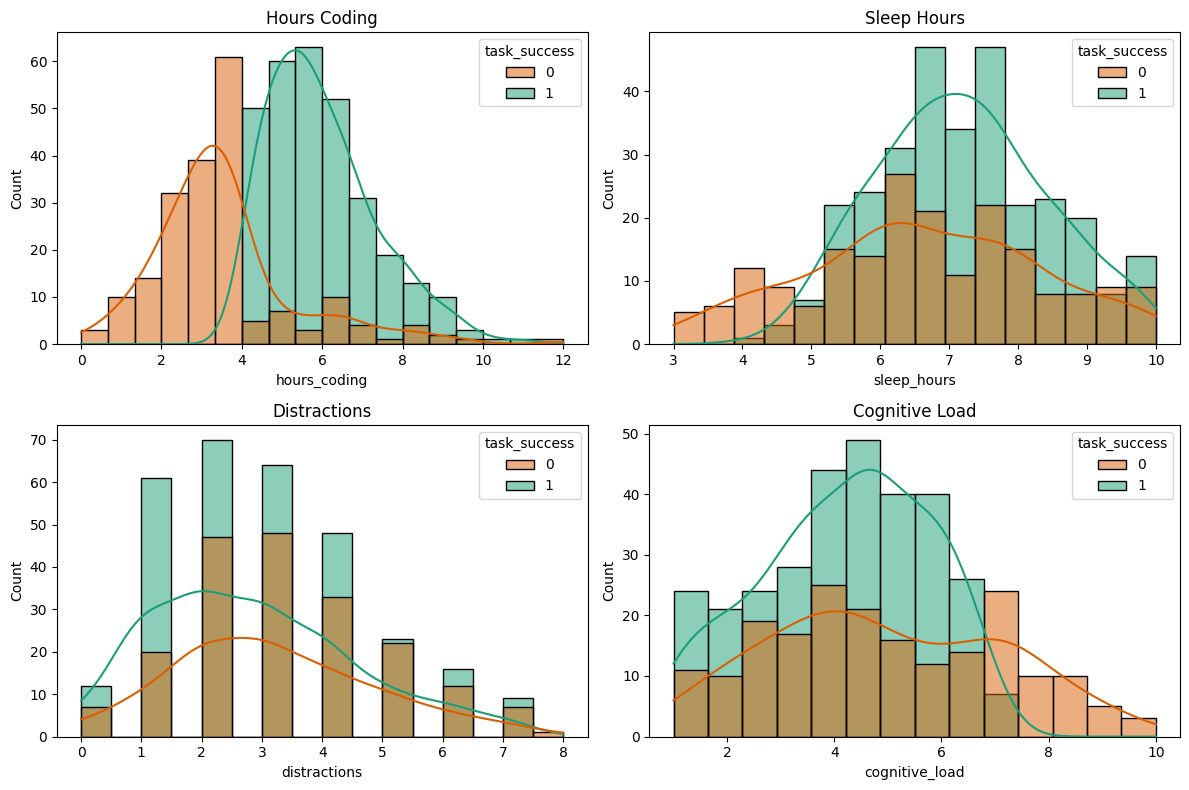

In [5]:
features = ["hours_coding", "sleep_hours", "distractions", "cognitive_load"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, features):
    sns.histplot(data=df, x=feature, hue="task_success", kde=True, ax=ax, palette=["#d95f02", "#1b9e77"])
    ax.set_title(feature.replace("_", " ").title())
plt.tight_layout()
plt.show()

These distributions show the operating range of work habits and cognitive load. The outcome coloring helps identify whether successful and unsuccessful records occupy different parts of each distribution.

## 6. Compare successful and unsuccessful tasks

,records,coding_hours,sleep_hours,distractions,commits,bugs_reported,ai_usage_hours,cognitive_load
task_success,,,,,,,,
Unsuccessful,197,3.53,6.64,3.19,3.47,1.1,1.19,4.96
Successful,303,5.98,7.19,2.83,5.35,0.7,1.72,4.20


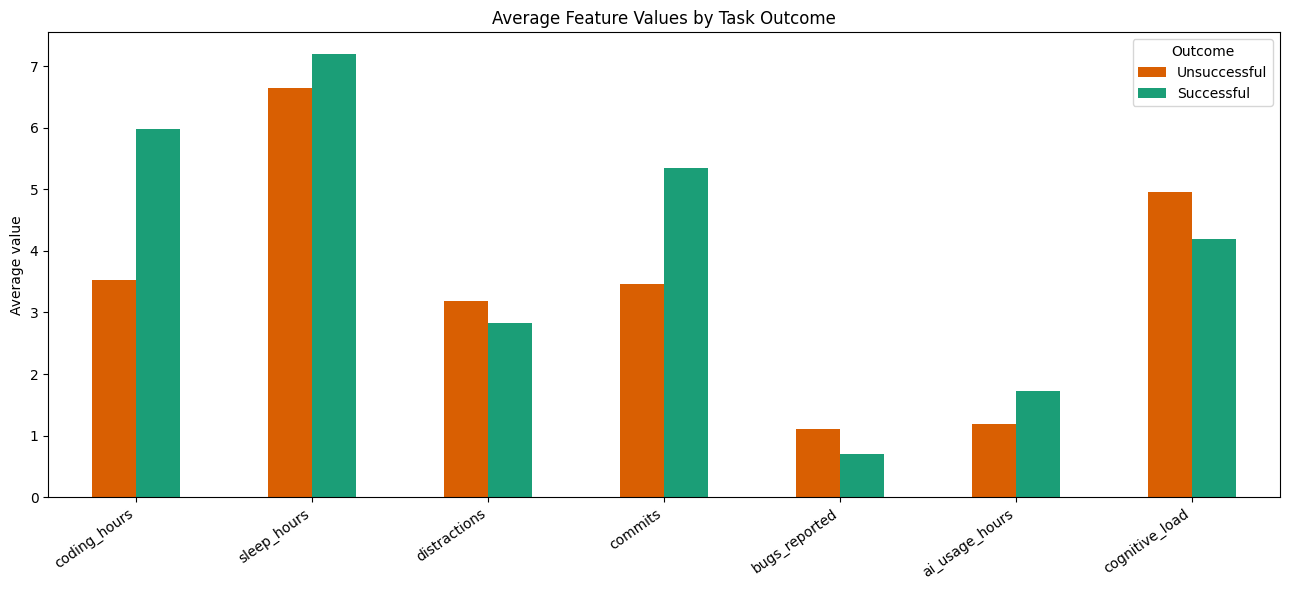

In [6]:
comparison = df.groupby("task_success").agg(
    records=("task_success", "size"),
    coding_hours=("hours_coding", "mean"),
    sleep_hours=("sleep_hours", "mean"),
    distractions=("distractions", "mean"),
    commits=("commits", "mean"),
    bugs_reported=("bugs_reported", "mean"),
    ai_usage_hours=("ai_usage_hours", "mean"),
    cognitive_load=("cognitive_load", "mean"),
).round(2)
comparison.index = comparison.index.map({0: "Unsuccessful", 1: "Successful"})
display(comparison)
comparison.drop(columns="records").T.plot(kind="bar", figsize=(13, 6), color=["#d95f02", "#1b9e77"])
plt.title("Average Feature Values by Task Outcome")
plt.ylabel("Average value")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

This table and chart provide the main productivity comparison. We should describe differences as associations in the report, because this observational dataset does not establish that one behavior causes task success.

## 7. Cognitive-load groups

,records,task_success_rate,avg_bugs,avg_distractions
cognitive_load_group,,,,
Low (1-3),117,0.641,0.513,2.154
Medium (4-6),277,0.682,0.856,2.921
High (7-10),106,0.368,1.245,4.028


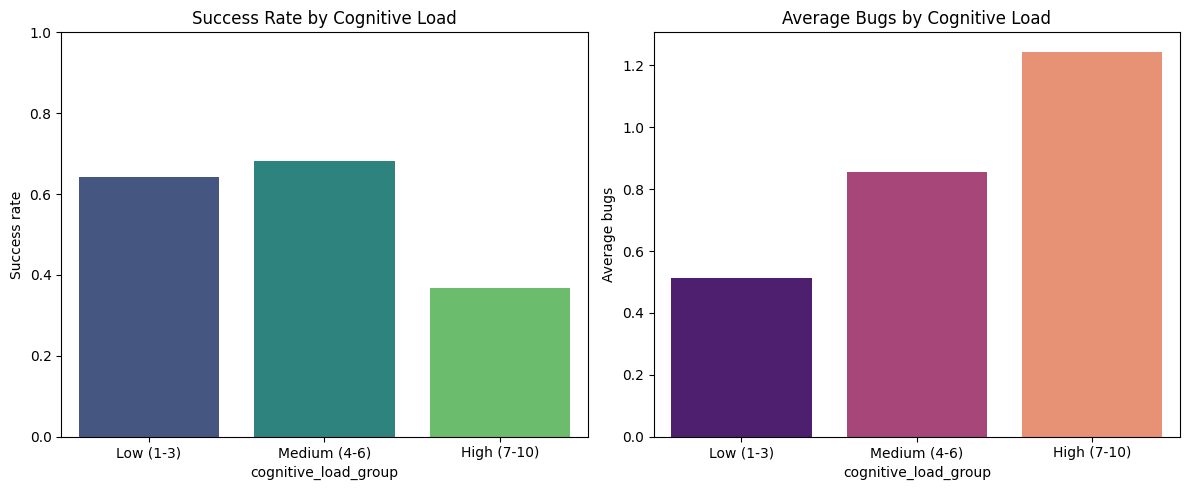

In [7]:
df["cognitive_load_group"] = pd.cut(df["cognitive_load"], bins=[0, 3, 6, 10], labels=["Low (1-3)", "Medium (4-6)", "High (7-10)"])
load_summary = df.groupby("cognitive_load_group", observed=False).agg(
    records=("task_success", "size"),
    task_success_rate=("task_success", "mean"),
    avg_bugs=("bugs_reported", "mean"),
    avg_distractions=("distractions", "mean"),
).round(3)
display(load_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=load_summary.reset_index(), x="cognitive_load_group", y="task_success_rate", ax=axes[0], hue="cognitive_load_group", legend=False, palette="viridis")
axes[0].set_ylim(0, 1)
axes[0].set_title("Success Rate by Cognitive Load")
axes[0].set_ylabel("Success rate")
sns.barplot(data=load_summary.reset_index(), x="cognitive_load_group", y="avg_bugs", ax=axes[1], hue="cognitive_load_group", legend=False, palette="magma")
axes[1].set_title("Average Bugs by Cognitive Load")
axes[1].set_ylabel("Average bugs")
plt.tight_layout()
plt.show()

The high-load group has the lowest observed success rate and the highest average bugs in this dataset. This is a useful operational signal for a dashboard, but it should be presented as a pattern requiring further validation.

## 8. Correlation overview

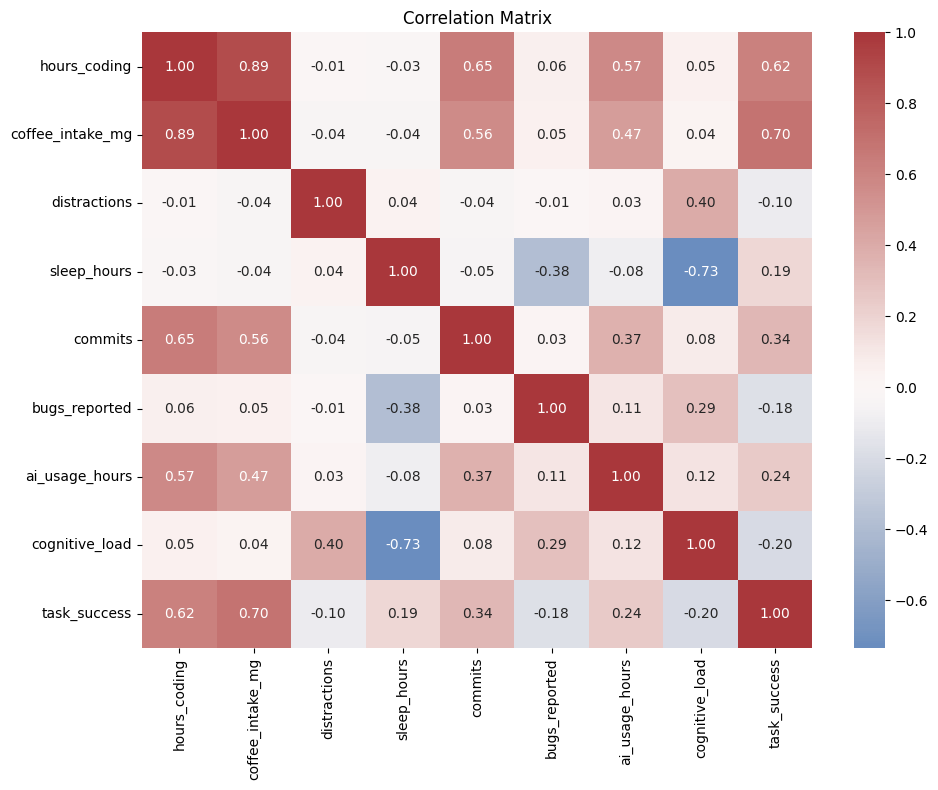

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.drop(columns="cognitive_load_group", errors="ignore").corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

Correlation measures linear association, not causation. Strong correlations can guide deeper questions, but they should not be interpreted as proof that a feature drives task success.

## Q&A
- **Is task success associated with work habits?** Yes. Successful records have higher average coding hours, commits and AI-tool usage, while unsuccessful records have more average bugs and slightly more distractions.
- **Is cognitive load relevant?** Yes. The high-load group shows a lower observed success rate and higher average bugs than the low- and medium-load groups.
- **Can this dataset prove causation?** No. It is observational and does not include an experimental design.

## Data Analysis Key Findings
- The dataset contains 500 validated records with no missing values or duplicate rows.
- There are 303 successful and 197 unsuccessful records, corresponding to a 60.6% observed success rate.
- Successful records average 5.98 coding hours, 5.35 commits and 0.70 bugs; unsuccessful records average 3.53 coding hours, 3.47 commits and 1.10 bugs.
- High cognitive-load records have a 36.8% success rate and 1.25 average bugs, compared with 68.2% success and 0.86 average bugs for the medium-load group.

## Insights or Next Steps
- Build the dashboard around early-warning indicators: cognitive load, bugs, distractions and task outcome.
- Validate these patterns with a larger longitudinal dataset containing developer and date identifiers before making workforce decisions.